# **Airborne Object Tracking Backbone Evaluation**

## **1. Overview**

This notebook evaluates a proposed backbone optimisation for the [AICrowd Airborne Object Tracking Challenge](https://www.aicrowd.com/challenges/airborne-object-tracking-challenge), a benchmark designed for long-range airborne object detection and tracking in autonomous Sense & Avoid (SAA) systems. Autonomous SAA systems are responsible for maintaining safe separation between aircraft and unforeseen obstacles during flight. While flight paths may be planned in advance, real-world operation in unconstrained airspace introduces the possibility of encountering unexpected airborne objects. In such cases, the system must perform situational awareness, decision-making, and evasive manoeuvre planning in real time. 

The evaluation in this notebook uses **Winning Solution (Optimised)** as the primary reference core_improvement. This implementation is based on the public [2021 winning solution](https://github.com/pdima/airborne_tracking_winning_solution) developed by Dmytro Poplavskiy, which achieved first place in the AICrowd Airborne Object Tracking Challenge. The original solution employed a segmentation-based detection and tracking pipeline *(SegTracker)* built around an ensemble of four specialised models:
* **HRNet-W32:** High-resolution convolutional backbone.
* **HRNet-W48:** Higher-capacity HRNet variant.
* **GerNet-M + BiFPN:** Multi-scale feature aggregation network.
* **DLA-60:** Deep Layer Aggregation backbone.

**Winning Solution (Optimised)** retains the original pretrained weights while introducing a corrected implementation of the [Temporal Shift Module (TSM)](https://github.com/mit-han-lab/temporal-shift-module) together with [MAX-AUTOTUNE CUDA Graph](https://docs.pytorch.org/docs/2.12/generated/torch.compile.html) compilation for accelerated inference. As a result, this implementation is not equivalent to the original 2021 competition-winning version and instead serves as the reference core_improvement for all experiments in this notebook.

The primary objective of the backbone evaluation presented in this notebook is to determine whether the original SegTracker ensemble can be replaced by smaller, more computationally efficient single-backbone architectures without sacrificing airborne object detection performance.

### **1.1. Example Airborne Encounter**

<div align="center">
  <img src="../docs/Images/Data_Viewer_Video.gif" width="700"/>
</div>

<p align="center">
  <em>Example Airborne Encounter from the Evaluation Dataset. The Target Aircraft Occupies Only a Few Pixels During the Early Stages of the Encounter.</em>
</p>


---

<br/>

## **2. Models Evaluated**

* **[MobileNetV4-S](https://github.com/d-li14/mobilenetv4.pytorch):** Lightweight CNN backbone representing the lowest-complexity deployment target.
* **[EfficientViT-M2](https://github.com/mit-han-lab/efficientvit):** Compact hybrid vision transformer providing a balance between efficiency and accuracy.
* **[ResNet-34](https://github.com/Moddy2024/ResNet-34):** Established convolutional backbone included as a widely recognised reference architecture.
* **[EfficientViT-B2](https://github.com/CVHub520/efficientvit):** Larger EfficientViT variant representing a higher-capacity transformer-based backbone.
* **[HRNet-W32](https://github.com/HRNet/HRNet-Image-Classification):** Single-model version of one of the original ensemble components, included to assess the contribution of ensembling.
* **Winning Solution (Optimised):** Optimised SegTracker ensemble baseline (HRNet-W32, HRNet-W48, GerNet-M + BiFPN, DLA-60).


---

<br/>

## **3. Evaluation Metrics**

* **AFDR:** Airborne Flight Detection Rate.
* **FPPI:** False Positives Per Image. (Must be ≤ 0.0005)
* **HFAR:** Horizontal False Alarm Rate. (Must be ≤ 0.5)
* **EDR:** Encounter-Level Detection Rate.

> ⚠️ ***Note:*** *Inference for all models requires a CUDA-capable GPU. While CPU-based loading of model weights is supported for inspection, full evaluation is computationally intensive.*


---

<br/>

## **4. Dataset**

The custom dataset used in this notebook is a curated hard subset of the full Airborne Object Tracking (AOT) dataset, specifically designed to stress-test model performance under the most demanding real-world conditions. Flights were selected to isolate encounters that represent the greatest challenge for vision-based detection and tracking systems.

### **4.1. Example Detection Progression**
|                                                      |                                                      |                                                      |
| :--------------------------------------------------: | :--------------------------------------------------: | :--------------------------------------------------: |
| ![Frame 1](../docs/Images/Data_Viewer_Picture_1.png) | ![Frame 2](../docs/Images/Data_Viewer_Picture_2.png) | ![Frame 3](../docs/Images/Data_Viewer_Picture_3.png) |
|                   Early Detection                    |                    Closing Distance                  |                       Near Range                     |

*The sequence above demonstrates how airborne targets gradually increase in apparent size throughout an encounter. Reliable early detection is particularly challenging because aircraft often occupy only a few pixels during the most safety-critical phase of the encounter.*

### **4.2. Hard Subset Selection Criteria**

- **Small Targets:** Airborne objects occupying only a few pixels per frame.
- **Multiple Targets:** Scenes containing more than one airborne object simultaneously.
- **Poor Visibility:** Flights affected by sun glare, adverse lighting, or challenging camera angles.

### **4.3. Dataset Summary**

The dataset is partitioned into a stratified 70/15/15 train/validation/test split to preserve the distribution of key difficulty factors across all subsets.

| Metric                   | Value   | Description                                                             |
|--------------------------|--------:|-------------------------------------------------------------------------|
| **Total Flights**        | **1618**| **Total number of flight sequences in the dataset**                     |
| Small Object Flights     | 662     | Flights containing at least one object with bounding box area ≤ 36.0px².|
| Below Horizon Flights    | 1053    | Flights containing at least one object at or below the horizon.         |
| Multi-Object Flights     | 627     | Flights containing more than one airborne object in at least one frame. |
| No Object Frames         | 354     | Flights containing at least one frame with no airborne object present.  |
| *Avg. Sequence Length*   | *17.77s*| *Average duration of each flight sequence.*                             |

---

<br/>

In [1]:
# Import Required Libraries.
import os
import sys

import cv2
import json
import torch
import random

from glob import glob
import matplotlib.pyplot as plt

# Because Life, Universe & Everything!
random.seed(42)

# Set Working Directory to Project Root.
os.chdir("..") 
PROJECT_ROOT = os.getcwd()

# Add Project Root to Path.
sys.path.insert(0, PROJECT_ROOT)

# Add Core Metric Folders to System Path.
sys.path.insert(0, os.path.join(PROJECT_ROOT, "core"))

# Import Local Project Funtions.
from logging_module import LogLevel, log
from src.data.download_data import main as downloadData
from notebooks.helpers.notebook_visualiser import main as visualise_results
from notebooks.helpers.notebook_helpers import (
    get_next_run_dir, load_combined_gt, resolve_local_flights,
    convert_results_to_metrics_format, prepare_subset, load_subset_summary,
    measure_predictor_complexity, build_extended_summary
)
 
# Confirm Project Root.
log(LogLevel.INFO, "core_improvement:imports", "Project Root Set: %s", PROJECT_ROOT)

<INFO ><core_improvement:imports> Project Root Set: /home/busatmd021/projects/2026/Vision-Based-Sense-and-Avoid


In [2]:
# Choose Which Model to Run
# --------------------------------------------------
# 0 -> Winning Solution Optimised (SegTracker Ensemble: HRNet32, HRNet48, GerNet-M + BiFPN, DLA60).
# 1 -> MobileNetV4 (Lightweight Detection Backbone).
# 2 -> EfficientVit-M2 (Medium-Weight Detection Backbone).
# 3 -> ResNet34 (Medium-Weight Detection Backbone).
# 4 -> EfficientVit-B2 (Heavy-Weight Detection Backbone).
# 5 -> HRNet-W32 (Heavy-Weight Detection Backbone).
SELECTED_MODEL = 1
model_list = ["winning_solution_star","mobilenetv4", "efficientvitm2", "resnet34", "efficientvitb2", "hrnetw32"]

# Evaluation Filtering.
MIN_SCORE = 0.60
DETECTION_THRESHOLD = 0.60
MIN_TRACK_LEN = 30

# Set Path to Desired Evaluation Dataset.
DATASET_PATH = "configs/datasets/training_subsets/test.txt"
DATASET_PARTS = ["part1", "part2", "part3"]

# Set Results Variables (Auto-Incrementing Run Directory).
RESULTS_DIR = "outputs/results/core_improvement/" + model_list[SELECTED_MODEL]
run_name = get_next_run_dir(RESULTS_DIR)

# Evaluation Output Folders.
EVAL_GT_DIR = os.path.join(RESULTS_DIR, run_name, "gt")
EVAL_RESULT_DIR  = os.path.join(RESULTS_DIR, run_name, "result")
EVAL_SUMMARY_DIR = os.path.join(RESULTS_DIR, run_name, "summaries")

# Print Summary Statement.
log(LogLevel.INFO, "core_improvement:config", "Configuration Loaded.")
print(f"  Model Selected : {model_list[SELECTED_MODEL]}")
print(f"  Dataset Path   : {DATASET_PATH}")
print(f"  Dataset Parts  : {DATASET_PARTS}")
print(f"  Run Name       : {run_name}")
print(f"  Results Path   : {RESULTS_DIR}")
print(f"  Min Score      : {MIN_SCORE}")
print(f"  Min Track Len  : {MIN_TRACK_LEN}")

<INFO ><core_improvement:config> Configuration Loaded.
  Model Selected : mobilenetv4
  Dataset Path   : configs/datasets/training_subsets/test.txt
  Dataset Parts  : ['part1', 'part2', 'part3']
  Run Name       : run2
  Results Path   : outputs/results/core_improvement/mobilenetv4
  Min Score      : 0.6
  Min Track Len  : 30


In [ ]:
# Download the Selected Flight Sequences.
downloadData(DATASET_PATH)


---

<br/>

## **5. Data Preparation and Preprocessing**

Before inference can begin, the dataset must be resolved from the flight ID list down to what is actually available on disk, and the ground truth must be filtered to match. This cell performs two steps:

**5.1. Flight Resolution:** Parses the `.txt` flight ID file produced by `data_builder.py`, cross-references each entry against the local `data/<part>/Images/` directories, and builds a lookup of every flight that is both listed and downloaded. Flights in the list that have not been downloaded are logged and skipped.

**5.2. Ground Truth Filtering:** Loads the `groundtruth.json` file from each part's `ImageSets/` folder and merges them into a single structure, retaining only the entries that correspond to locally available flights. Entries for flights not on disk are silently skipped - this is expected, as the ground truth files reference the full AOT dataset rather than just the downloaded subset.

In [3]:
# Find all Available Sequences from the Provided Dataset.
local_flights = resolve_local_flights(DATASET_PATH, PROJECT_ROOT)

# Add Spacing in Console Output for Readability.
print()

# Log How Many Flights were Found & are Ready for Inference.
log(LogLevel.INFO, "core_improvement:preprocessing", "Flights Ready for Inference: %d", len(local_flights))

# Preview the First 5 Flights to Confirm Dataset is Correct.
for name, info in list(local_flights.items())[:5]:
    # Count No. Images in the Flight Directory.
    n_imgs = len(list(info["images_dir"].glob("*.png")))

    # Print Flight Part, Name, & No. Images.
    print(f"  [{info['part']}]  {name}  ({n_imgs} images)")

# If there are More than 5 Flights, Log How Many Additional Ones Exist.
if len(local_flights) > 5:
    log(LogLevel.DEBUG, "core_improvement:preprocessing", " ... and %d more.", len(local_flights) - 5)

# Load & Filter Ground Truth to Include Local Flights Only. 
combined_gt = load_combined_gt(DATASET_PARTS, local_flights, PROJECT_ROOT)
log(LogLevel.INFO, "core_improvement:preprocessing", "Flights in Filtered Ground Truth: %d", len(combined_gt['samples']))

# Build Set of Image Filenames That Physically Exist on Disk.
all_images = {name for f in local_flights.values() for name in f["image_names"]}

# Cull GT Entities to Only Those With a Corresponding Image on Disk.
before = sum(len(flight["entities"]) for flight in combined_gt["samples"].values())

for flight_hash, flight_data in combined_gt["samples"].items():
    flight_data["entities"] = [
        e for e in flight_data["entities"]
        if e["img_name"] in all_images
    ]

after = sum(len(flight["entities"]) for flight in combined_gt["samples"].values())

# Report How Many Images were Removed. 
log(LogLevel.INFO, "core_improvement:preprocessing",
    "GT Culled: %d -> %d entities (%d removed for missing images).", before, after, before - after)

# Save the Filtered Ground Truth to the Evaluation Folder.
os.makedirs(EVAL_GT_DIR, exist_ok=True)
gt_out_path = os.path.join(EVAL_GT_DIR, "groundtruth.json")

# Copy the Ground Truth Values to the .json.
with open(gt_out_path, "w") as f:
    json.dump(combined_gt, f)

# Print Success Message.
log(LogLevel.INFO, "core_improvement:preprocessing", "Ground Truth Saved: %s", gt_out_path)

<INFO ><notebook_helpers:resolve_flights> 4 Flights on Disk. 0 Not Found. (Run the Download Cell to Fetch Missing Flights).

<INFO ><core_improvement:preprocessing> Flights Ready for Inference: 4
  [part1]  part11b3a52c0f1764533b32e36992b17b6e1  (1198 images)
  [part1]  part1036edfd6ece44c37b8ca9562fd701682  (1199 images)
  [part1]  part159e37841f5394c1497566753ba15172d  (101 images)
  [part3]  part354be71509266480ca13ae3fec487af47  (242 images)

<INFO ><notebook_helpers:load_gt> 4 kept / 4154 total.
<INFO ><core_improvement:preprocessing> Flights in Filtered Ground Truth: 4
<INFO ><core_improvement:preprocessing> GT Culled: 5236 -> 3181 entities (2055 removed for missing images).
<INFO ><core_improvement:preprocessing> Ground Truth Saved: outputs/results/core_improvement/mobilenetv4/run2/gt/groundtruth.json



---

<br/>

## **6. Evaluate Models**

### **6.1. Run Inference**

This section runs inference for the selected backbone configuration. The evaluation is controlled via the `SELECTED_MODEL` parameter, which determines which backbone is instantiated and evaluated within the shared detection pipeline. All models are evaluated under a consistent inference setup to ensure fair comparison across backbone architectures, using the same preprocessing, detection pipeline, and evaluation metrics.

**6.1.1. Prepare evaluation directory and configure environment variables.**

In [4]:
# Create a Directory where all Evaluation Flight Data will be Stored.
EVAL_DATA_DIR = os.path.join(RESULTS_DIR, run_name, "data")
os.makedirs(EVAL_DATA_DIR, exist_ok=True)

# Link Each Local Flight's Image Folder into the Evaluation Directory.
for folder_name, info in local_flights.items():
    link_path = os.path.join(EVAL_DATA_DIR, folder_name)
    if not os.path.exists(link_path):
        os.symlink(info["images_dir"], link_path)

# Set Environment Variables that AirbornePredictor and SelectedModelPredictor Read.
os.environ["TEST_DATASET_PATH"] = EVAL_DATA_DIR
os.environ["INFERENCE_OUTPUT_PATH"] = RESULTS_DIR
os.environ["DATASET_ENV"] = run_name
os.environ["MIN_TRACK_LEN"] = str(MIN_TRACK_LEN)
os.environ["MIN_SCORE"] = str(MIN_SCORE)
os.environ["DETECTION_THRESHOLD"] = str(DETECTION_THRESHOLD)

# Limit Inference to Only the Specified Flights.
os.environ["PARTIAL_RUN_FLIGHTS"] = ",".join(local_flights.keys())

# Print Summary Statement.
log(LogLevel.INFO, "core_improvement:inference", "Environment Configured.")
print(f"  Test Data Path     : {EVAL_DATA_DIR}")
print(f"  Flights to Process : {len(local_flights)}")
print(f"  MIN_SCORE          : {MIN_SCORE}")
print(f"  MIN_TRACK_LEN      : {MIN_TRACK_LEN}")

<INFO ><core_improvement:inference> Environment Configured.
  Test Data Path     : outputs/results/core_improvement/mobilenetv4/run2/data
  Flights to Process : 4
  MIN_SCORE          : 0.6
  MIN_TRACK_LEN      : 30



<br/>

**6.1.2. Run model inference across all evaluation flights using the selected configuration.**

> ⚠️ ***This cells requires a CUDA GPU and will take several hours to complete.*** *Skip this cell if inference has already been run and results are present in `RESULTS_DIRS`.*

In [5]:
# Import Model Classes.
from src.core_improvement.resnet34.resnet34_test import ResNet34Predictor
from src.core_improvement.hrnetw32.hrnet_w32_test import HRNetW32Predictor
from src.core_improvement.mobilenetv4.mobilenet_test import MobileNetV4Predictor
from src.core_improvement.winning_solution_star.seg_test import WinningSolutionPredictor
from src.core_improvement.efficientvitm2.efficientvit_m2_test import EfficientViTM2Predictor
from src.core_improvement.efficientvitb2.efficientvit_b2_test import EfficientViTB2Predictor

# Check GPU is CUDA Enabled.
if torch.cuda.is_available():
    log(LogLevel.INFO, "core_improvement:device_check", "CUDA-Enabled GPU is Available.")
    print(f"  GPU Name: {torch.cuda.get_device_name(0)}.")
    print(f"  CUDA Version: {torch.version.cuda}.")
else:
      log(LogLevel.WARNING, "core_improvement:device_check", "No CUDA-Enabled GPU Found, Using CPU Instead.")

/home/busatmd021/projects/2026/Vision-Based-Sense-and-Avoid/.venv/lib/python3.11/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


<INFO ><core_improvement:device_check> CUDA-Enabled GPU is Available.
  GPU Name: NVIDIA GeForce RTX 5060 Ti.
  CUDA Version: 12.8.


In [6]:
# Map Model Selection to Predictor Classes.
MODEL_MAP = {
    0: WinningSolutionPredictor, # Optimised Baseline.
    1: MobileNetV4Predictor,     # MobileNet v4.
    2: EfficientViTM2Predictor,  # EfficientVit m2.
    3: ResNet34Predictor,        # ResNet34.
    4: EfficientViTB2Predictor,  # EfficientVit b2.
    5: HRNetW32Predictor         # HRNet-W32.
}

# Validate Selection.
if SELECTED_MODEL not in MODEL_MAP:
    log(LogLevel.ERROR, "core_improvement:inference", "Invalid SELECTED_MODEL: %s.", SELECTED_MODEL)
    raise ValueError("Please Select a Valid Model Index.")

# Initialise Predictor.
predictor = MODEL_MAP[SELECTED_MODEL]()

# Load Models Before Measuring Complexity.
predictor.inference_setup()

# Measure the Current Model's Complexity.
print()
complexity = measure_predictor_complexity(predictor)

# Run Inference Over all Flights.
print()
predictor.run()

# Print Summary Statement.
log(LogLevel.INFO, "core_improvement:inference", "Inference Complete.")
print(f"  Raw Results Saved to: {os.path.join(RESULTS_DIR, run_name)}\n")

# Set Results Directories. 
RAW_RESULTS_PATH = os.path.join(RESULTS_DIR, run_name, "result.json")
METRICS_RESULTS_PATH = os.path.join(EVAL_RESULT_DIR, "result.json")

# Ensure Output Directory Exists.
os.makedirs(EVAL_RESULT_DIR, exist_ok=True)

# Copy the Results File.
convert_results_to_metrics_format(RAW_RESULTS_PATH, METRICS_RESULTS_PATH)

# Print Summary Statement.
log(LogLevel.INFO, "core_improvement:inference", "Results Copied to Metrics Directory.")
print(f"  Metrics-Ready Results Stored at : {METRICS_RESULTS_PATH}")

<INFO ><mobilenetv4:inference_setup> Segmentation Weights Loaded: configs/models/core_improvement/mobilenetv4/mobilenetv4_conv_small.pt
<INFO ><mobilenetv4:inference_setup> Transform Model Loaded.
<INFO ><mobilenetv4:inference_setup> MobileNetV4Predictor Ready.

<INFO ><notebook_helpers:measure_complexity> [MobileNetV4-Conv-Small (segmentation)] Params: 1,560,656 total / 1,560,656 trainable | GFLOPs: 41.598 | GMACs: 20.799
<INFO ><notebook_helpers:measure_complexity> [ResNet34-TSM Transform (model_transform)] Params: 21,281,475 total / 21,281,475 trainable | GFLOPs: 150.135 | GMACs: 75.067
<INFO ><notebook_helpers:measure_predictor_complexity> Total - Params: 22,842,131 | GFLOPs: 191.733 | GMACs: 95.866

<INFO ><mobilenetv4:inference_setup> Segmentation Weights Loaded: configs/models/core_improvement/mobilenetv4/mobilenetv4_conv_small.pt
<INFO ><mobilenetv4:inference_setup> Transform Model Loaded.
<INFO ><mobilenetv4:inference_setup> MobileNetV4Predictor Ready.


Flight part11b3a52c0f1764533b32e36992b17b6e1:   0%|          | 1/1198 [00:00<03:31,  5.67it/s]Autotune Choices Stats:
{"num_choices": 2, "num_triton_choices": 0, "best_kernel": "addmm", "best_time": 0.015807999297976494}
AUTOTUNE addmm(784x2, 784x1024, 1024x2)
strides: [0, 1], [1024, 1], [1, 1024]
dtypes: torch.float16, torch.float16, torch.float16
  addmm 0.0158 ms 100.0% 
  bias_addmm 0.0945 ms 16.7% 
SingleProcess AUTOTUNE benchmarking takes 0.1745 seconds and 0.0001 seconds precompiling for 2 choices
Autotune Choices Stats:
{"num_choices": 2, "num_triton_choices": 0, "best_kernel": "bias_addmm", "best_time": 1.1755199432373047}
AUTOTUNE addmm(78848x256, 78848x1152, 1152x256)
strides: [0, 1], [1152, 1], [1, 1152]
dtypes: torch.float16, torch.float16, torch.float16
  bias_addmm 1.1755 ms 100.0% 
  addmm 1.5611 ms 75.3% 
SingleProcess AUTOTUNE benchmarking takes 0.1066 seconds and 0.0001 seconds precompiling for 2 choices
Autotune Choices Stats:
{"num_choices": 2, "num_triton_choices"


<INFO ><notebook_helpers:record_fps> FPS - Mean: 29.9 | Std: 1.4 | Min: 5.0 | Max: 32.0 | P95: 31.3 (2686 frames)

<INFO ><core_improvement:inference> Inference Complete.


  Raw Results Saved to: outputs/results/core_improvement/mobilenetv4/run2

<INFO ><notebook_helpers:convert_results> Centre-Formated Result Conversion Complete.
<INFO ><core_improvement:inference> Results Copied to Metrics Directory.
  Metrics-Ready Results Stored at : outputs/results/core_improvement/mobilenetv4/run2/result/result.json



---

<br/>

## **7. Run Metrics Evaluation**

Run the official AICrowd evaluation metrics against the ground truth for each dataset part, saving per-part summaries to `SUMMARIES_DIR`.

In [7]:
# Locate the Competition Metrics Script.
metrics_script = os.path.join(PROJECT_ROOT, "core/metrics/run_airborne_metrics.py")

# Call the Competition Metrics Script.
!python3 {metrics_script} \
    --dataset-folder   {EVAL_GT_DIR} \
    --results-folder   {EVAL_RESULT_DIR} \
    --summaries-folder {EVAL_SUMMARY_DIR} \
    --min-score        {MIN_SCORE} \
    --min-track-len    {MIN_TRACK_LEN}

# Print Message on Completion. 
log(LogLevel.INFO, "core_improvement:evaluation", "Metrics Complete.")

2026-06-07 20:58:03,206:INFO:run_airborne_metrics.py:160 Encounter ground truth: outputs/results/core_improvement/mobilenetv4/run2/gt/groundtruth_with_encounters_maxRange700_maxGap3_minEncLen30.csv
2026-06-07 20:58:03,207:INFO:calculate_encounters.py:83 Asserting outputs/results/core_improvement/mobilenetv4/run2/gt/groundtruth.json format
2026-06-07 20:58:03,207:INFO:pandas_utils.py:87 Reading ground truth
2026-06-07 20:58:03,207:INFO:pandas_utils.py:61 Reading provided outputs/results/core_improvement/mobilenetv4/run2/gt/groundtruth.json
2026-06-07 20:58:03,207:INFO:pandas_utils.py:68 Loading .json
2026-06-07 20:58:03,214:INFO:pandas_utils.py:75 Normalizing json. This operation is time consuming. The result .csv will be saved Please consider providing .csv file next time
2026-06-07 20:58:03,259:INFO:calculate_encounters.py:268 Saving groundtruth in .csv format, please use .csv in the future
2026-06-07 20:58:03,281:INFO:calculate_encounters.py:272 Filtering ground truth to get intruder


---

<br/>

## **8. Benchmarking Summary**

Display the aggregated statistics across all three parts of the dataset in order to provide a measure of performance on the full hardened dataset. Additionally, a random sample of results is generated using both the ground truth bounding boxes and the predicted ones, enabling a visual analysis of the model’s performance.

In [8]:
# Find the Summary JSON in the Summaries Directory.
summary_files = glob(os.path.join(EVAL_SUMMARY_DIR, "*.json"))

# Check that the Summary Files Exist.
if not summary_files:
    log(LogLevel.ERROR, "core_improvement:summary", "No Summary Files Found! Run Inference First.")
else:
    # Build Summary DataFrame.
    summary_df = build_extended_summary(
        summary_json_path = summary_files[0],
        run_dir           = os.path.join(RESULTS_DIR, run_name),
        complexity        = complexity,
        output_csv_path   = os.path.join(EVAL_SUMMARY_DIR, "core_improvement_benchmark_summary.csv"),
    )
 
    # Print Summary to Console.
    print("\n" + "=" * 60)
    print(" NEW BACKBONE MODEL - TEST DATASET BENCHMARK SUMMARY")
    print("=" * 60)
    display(summary_df.set_index("Metric"))

<INFO ><notebook_helpers:build_extended_summary> Extended Summary Saved to: outputs/results/core_improvement/mobilenetv4/run2/summaries/core_improvement_benchmark_summary.csv

 NEW BACKBONE MODEL - TEST DATASET BENCHMARK SUMMARY


,Value,Status
Metric,,
Detection Score,0.6018,
AFDR (Airborne Flight Detection Rate),0.7300,
FPPI (False Positives Per Image),0.000000,PASS (≤ 0.0005)
HFAR (Horizontal False Alarm Rate),0.0000,PASS (≤ 0.5)
EDR - All Scenarios,0.5000,
EDR - Above Horizon,1.0000,
EDR - Below Horizon,0.5000,
Total Aircraft Detected,1933,
Total Aircraft in Dataset,2648,



<INFO ><visualise_detections:main> Loading Results CSV: outputs/results/core_improvement/mobilenetv4/run2/result/result.csv
<INFO ><visualise_detections:main> Loaded 2013 Detections across 2013 Unique Frames.
<INFO ><visualise_detections:main> Loading Ground Truth CSV: outputs/results/core_improvement/mobilenetv4/run2/gt/groundtruth.csv
<INFO ><visualise_detections:main> Loaded 3089 Ground Truth BBoxes across 2648 Unique Frames.

<INFO ><visualise_detections:main> Sampled 10 Frames for Visualisation.

Processing Frame 1/10  (1551797429583591561036edfd6ece44c37b8ca9562fd701682.png)
Processing Frame 2/10  (15507622061702608761b3a52c0f1764533b32e36992b17b6e1.png)
Processing Frame 3/10  (15507621885316753561b3a52c0f1764533b32e36992b17b6e1.png)
Processing Frame 4/10  (1551797463529114097036edfd6ece44c37b8ca9562fd701682.png)
Processing Frame 5/10  (15507622396510221691b3a52c0f1764533b32e36992b17b6e1.png)
Processing Frame 6/10  (15507622334951948871b3a52c0f1764533b32e36992b17b6e1.png)
Proces

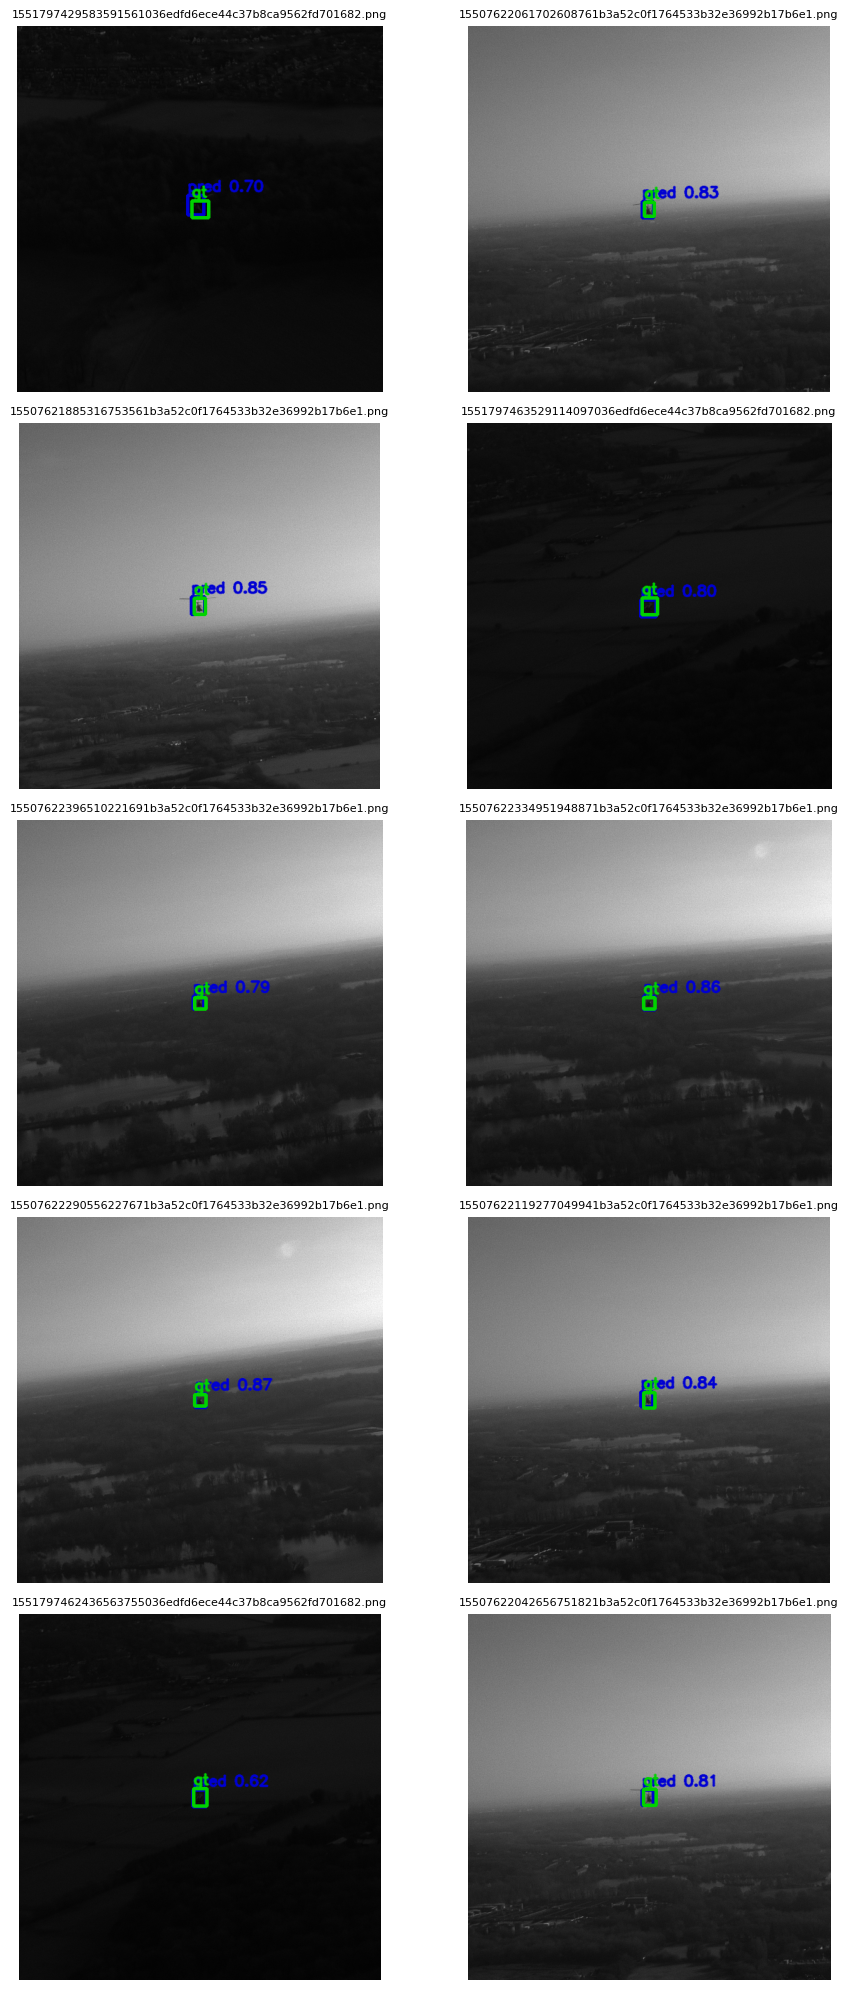

In [9]:
# Set Visualisations Folder Path. 
VISUALISER_DIR = os.path.join(RESULTS_DIR, run_name, "visualisations")

# Make & Save the Model Prediction Overlay Pictures.
visualise_results(
  results_csv = os.path.join(EVAL_RESULT_DIR, "result.csv"),
  groundtruth_csv = os.path.join(EVAL_GT_DIR, "groundtruth.csv"),
  images_dir = EVAL_DATA_DIR,
  output_dir = VISUALISER_DIR
)

# Get Image Files (Sorted for Consistency).
image_files = sorted([f for f in os.listdir(VISUALISER_DIR) if f.endswith(".png")])

# Limit the Number of Images to 10 to Fit a Grid of 2 Columns by 5 Rows.
image_files = image_files[:10]
cols = 2
rows = 5

# Create a Matplotlib Figure with the Specified Grid Size & Figure Dimensions.
fig, axes = plt.subplots(rows, cols, figsize=(10, 20))

# Iterate Over each Subplot Axis & Corresponding Image Index.
for i, ax in enumerate(axes.flatten()):
    if i < len(image_files):
        # Build the Full Image Path.
        img_path = os.path.join(VISUALISER_DIR, image_files[i])
        
        # Read + Convert BGR --> RGB.
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        # Display the Image in the Current Subplot.
        ax.imshow(img)

        # Clean Up the Image Filename to Show a Simpler Title.
        clean_name = image_files[i].split('_', 2)[-1]
        ax.set_title(clean_name, fontsize=8)

        # Hide the Axis Ticks & Labels for a Cleaner Look.
        ax.axis("off")
    else:
        # If there are Fewer Images than Grid Spaces, Hide Unused Axes.
        ax.axis("off")

# Adjust Spacing Between Subplots to Prevent Overlap.
plt.tight_layout()

# Display the Grid of Images.
plt.show()


---

<br/>

## **9. Backbone Evaluation Results**

The results below are reported on the remaining **held-out test set (243 flights)** after excluding the hardened training subset used during model development. This represents all available unseen evaluation data.

| Model                          | Params (M) | GFLOPs  | FPS    | AFDR    | FPPI        | EDR    |
|--------------------------------|------------|---------|--------|---------|-------------|--------|
| MobileNetV4-S                  | 1.56       | 41.60   | 26.75  | 53.58%  | 0.0000208   | 12.98% |
| EfficientViT-M2                | 4.11       | 33.72   | 3.60   | 5.93%   | 0           | 3.37%  |
| EfficientViT-B2                | 15.17      | 168.36  | 16.49  | 57.64%  | 0.035936    | 14.90% |
| ResNet34                       | 21.55      | 381.25  | 20.75  | 51.88%  | 0.030279    | 12.02% |
| HRNet-W32                      | 29.56      | 42.45   | 11.00  | 60.07%  | 0.000021    | 15.87% |
| Winning Solution (Optimised)   | 127.10     | 3286.45 | 7.04   | 71.51%  | 0.000021    | 59.62% |

*Results evaluated at a minimum detection confidence of 0.60 and a minimum track length of 30 frames (≈ 3 seconds at 10 fps).*

---